Multiple Linear Regression 

As we know, when we use more than one independent variable in our regression analysis, it is called multiple regression. In this notebook, we demonstrate how to perform multiple regression analysis with 2 independent variables and also determine the effect of adding a new variable to our model: does it make our regression model more efficient or not

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn

import tha data set into dataframe

In [2]:
data = pd.read_csv("1.02. Multiple linear regression.csv")

In [3]:
data.head()

,SAT,GPA,"Rand 1,2,3"
0,1714,2.40,1
1,1664,2.52,3
2,1760,2.54,3
3,1685,2.74,3
4,1693,2.83,2


In [4]:
data.describe()

,SAT,GPA,"Rand 1,2,3"
count,84.000000,84.000000,84.000000
mean,1845.273810,3.330238,2.059524
std,104.530661,0.271617,0.855192
min,1634.000000,2.400000,1.000000
25%,1772.000000,3.190000,1.000000
50%,1846.000000,3.380000,2.000000
75%,1934.000000,3.502500,3.000000
max,2050.000000,3.810000,3.000000


let's define dependent and independed variable

In [5]:
y = data['GPA']
x1 = data[['SAT', 'Rand 1,2,3']]
x2 = data['SAT']
x3 = data['Rand 1,2,3']

In [6]:
x = sm.add_constant(x1)
result = sm.OLS(y,x).fit()
result.summary()



<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    GPA   R-squared:                       0.407
Model:                            OLS   Adj. R-squared:                  0.392
Method:                 Least Squares   F-statistic:                     27.76
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           6.58e-10
Time:                        14:08:36   Log-Likelihood:                 12.720
No. Observations:                  84   AIC:                            -19.44
Df Residuals:                      81   BIC:                            -12.15
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2960      0.417      0.710      0.480      -0.533       1.125
SAT            0.0017      0.000      7.432      0.000       0.001       0.002
Rand 1,2,3    -0.0083      0.027     -0.304      0.762      -0.062       0.046
==============================================================================
Omnibus:                       12.992   Durbin-Watson:                   0.948
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               16.364
Skew:                          -0.731   Prob(JB):                     0.000280
Kurtosis:                       4.594   Cond. No.                     3.33e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.33e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

you can see the p>|t| of Rand 1,2,3 is 0.762 and coef is also -0.0083 which means this variable do not add any value in our model so we can drop it. Always remeber to look for adj. R square  

In [7]:
x_const = sm.add_constant(x2)
resultI = sm.OLS(y, x_const).fit()
resultI.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    GPA   R-squared:                       0.406
Model:                            OLS   Adj. R-squared:                  0.399
Method:                 Least Squares   F-statistic:                     56.05
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           7.20e-11
Time:                        14:08:36   Log-Likelihood:                 12.672
No. Observations:                  84   AIC:                            -21.34
Df Residuals:                      82   BIC:                            -16.48
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2750      0.409      0.673      0.503      -0.538       1.088
SAT            0.0017      0.000      7.487      0.000       0.001       0.002
==============================================================================
Omnibus:                       12.839   Durbin-Watson:                   0.950
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               16.155
Skew:                          -0.722   Prob(JB):                     0.000310
Kurtosis:                       4.590   Cond. No.                     3.29e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.29e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

The std err and P>|t| in this regression are 0.000, which means the SAT score is a significant variable for our model 



regression line for SAT and GPA score

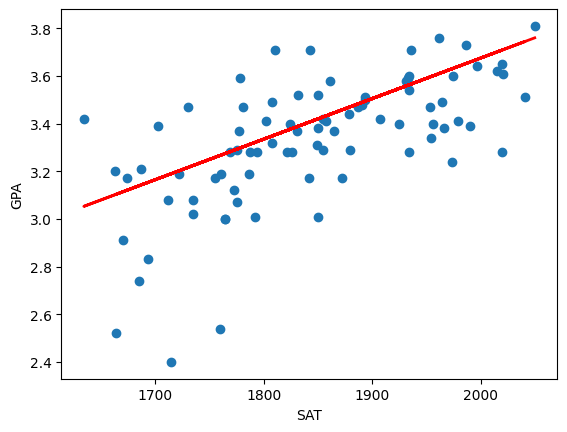

In [12]:
y_hat = 0.2750 + 0.0017 * data['SAT']
plt.scatter(x2, y)
fig = plt.plot(x2, y_hat, c = 'red', lw = 2)
plt.xlabel('SAT')
plt.ylabel('GPA')
plt.show()

With the help of this (yhat = 0.0017 * x2 + 0.2750) regression equation of y on x we can also predict the value of y(GPA) with the help of given x(SAT)